Predict future averge price of Rice per Kg and per Pyi monthly by using SARIMAX model and Linear Regression Model
* According to the result, the Linear Regression Model is better than SARIMAX model.
* As the result, the price of rice is mostly effect on the price of cereals and tubers.

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
# SARIMAX
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


### Preparing for Prediction

In [10]:
DRM = data.copy()
DRM = DRM[(DRM['Exact Commodity']).str.strip()=='Rice']
DRM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
7,1/15/2008,Magway,Magway,Magway,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,604.17,0.3394
10,1/15/2008,Magway,Magway,Yenanchaung,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,900.00,0.5056
12,1/15/2008,Magway,Pakokku,Pakhangyi,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,541.67,0.3043
14,1/15/2008,Rakhine,Maungdaw,Alel Than Kyaw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,460.00,0.2584


In [11]:
DRM = DRM[['date', 'price']]
DRM['date'] = pd.to_datetime(DRM['date'])
mask = (DRM['date'] >= obv_st_date) & (DRM['date'] <= obv_end_date)
DRM = DRM.loc[mask]
DRM = DRM.set_index('date')
DRM.head()

,price
date,
2008-01-15,400.00
2008-01-15,604.17
2008-01-15,900.00
2008-01-15,541.67
2008-01-15,460.00


In [12]:
DRM.shape

(6176, 1)

In [13]:
DRM = DRM.resample('MS').mean()
DRM.head()

,price
date,
2008-01-01,486.208750
2008-02-01,476.178696
2008-03-01,420.357600
2008-04-01,487.482000
2008-05-01,521.175862


In [14]:
DRM.shape

(169, 1)

In [15]:
price = DRM['price']
date = DRM.index

### Normalization Data

In [16]:
scaler = MinMaxScaler()

In [17]:
DRM = scaler.fit_transform(DRM)
DRM = pd.DataFrame(DRM)
DRM.head()

,0
0,0.302965
1,0.282652
2,0.169602
3,0.305544
4,0.373781


In [18]:
DRM['date'] = date
DRM = DRM.set_index('date')
DRM.columns = ['price']
DRM.head()

,price
date,
2008-01-01,0.302965
2008-02-01,0.282652
2008-03-01,0.169602
2008-04-01,0.305544
2008-05-01,0.373781


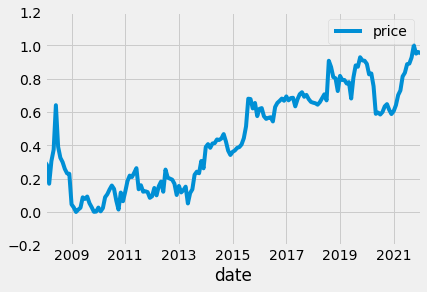

In [19]:
DRM.plot(grid = True)
plt.show()

It has upward trend. So it has difference =1

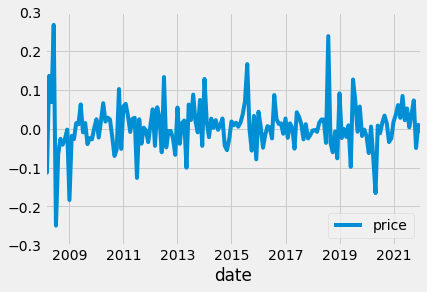

In [20]:
DRM_diff1 = DRM.diff(1).dropna()
DRM_diff1.plot(grid = True)
plt.show()

##### Checking Random Walk

In [21]:
RW_DRM= adfuller(DRM_diff1)
RW_DRM[1] # print P-value. If p-value<5%, reject null hypothesis

4.17082832734007e-10

### Plotting ACF and PACF

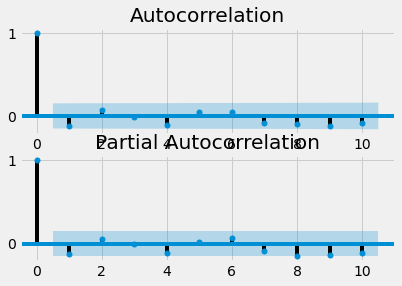

In [22]:
fig, axes=plt.subplots(2,1)
plot_acf(DRM_diff1, lags=10, ax=axes[0])
plot_pacf(DRM_diff1, lags=10, ax=axes[1])
plt.show()

### Using SARIMAX

#### AIC, BIC

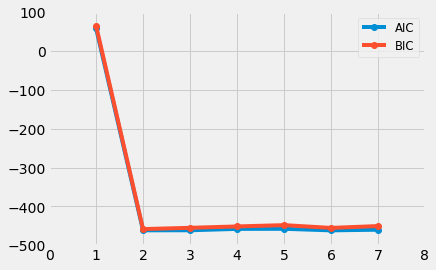

In [23]:
AIC, BIC = AIC_BIC_withOrderRange(DRM, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [24]:
AIC, BIC

(array([ 268.44121266,   58.44266392, -461.43936831, -461.29270872,
        -457.77793324, -457.53398369, -461.52400883, -459.87995616]),
 array([ 271.57111138,   64.70246135, -458.31540433, -455.04478076,
        -451.51813581, -448.14428754, -455.27608087, -450.50806422]))

We will run again 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [25]:
mod_orders = [
    (0,1,0),
    (0,1,1),
    (1,0,0),
    (1,0,1),
    (1,1,0),
    (1,1,1)
]

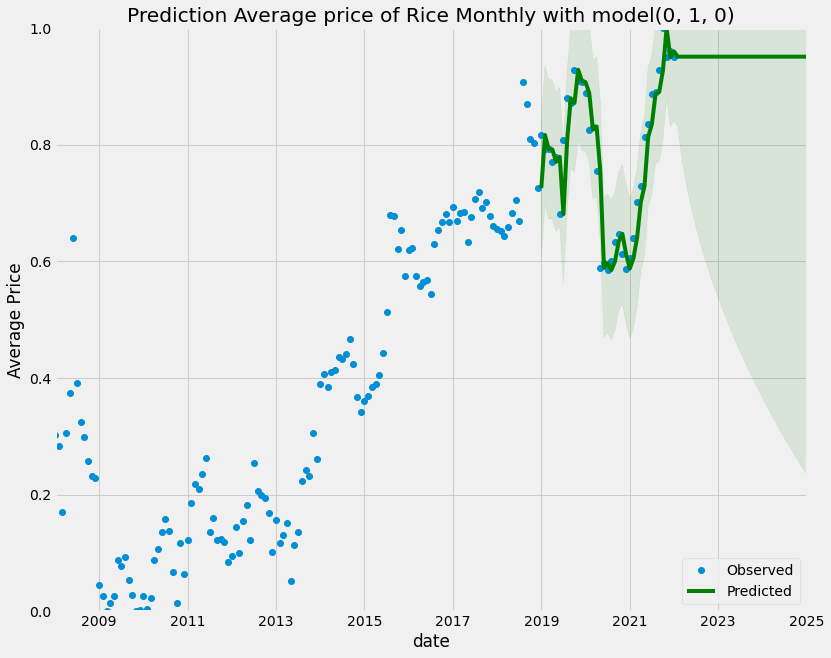

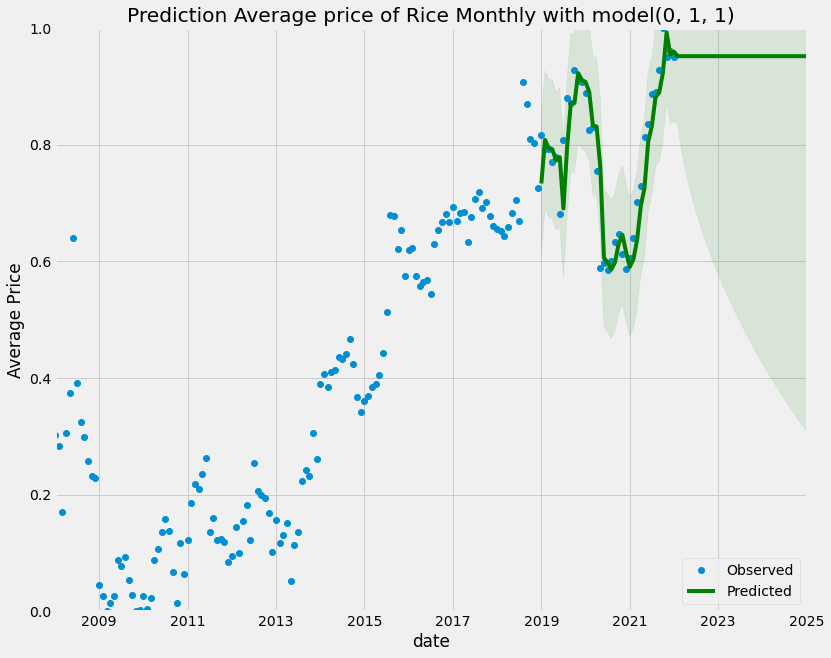

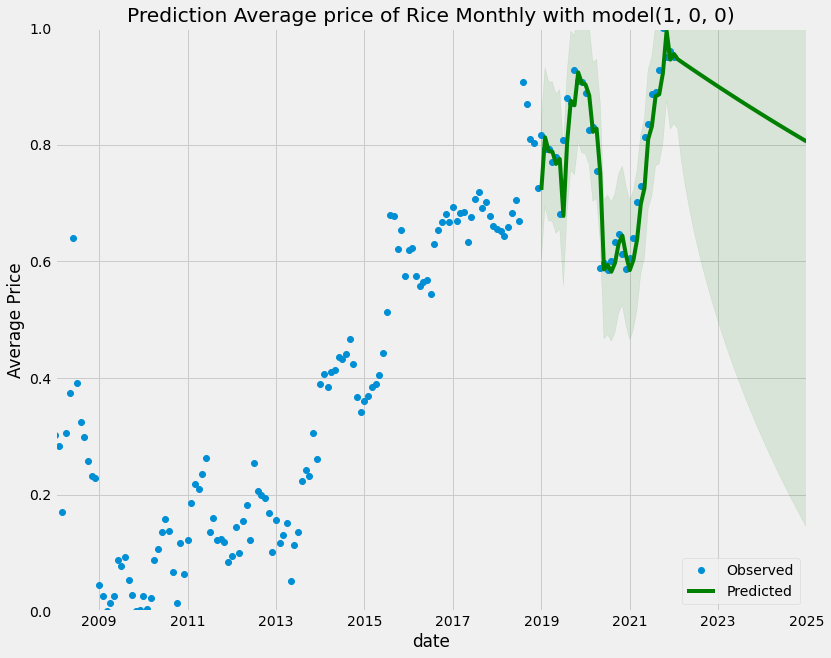

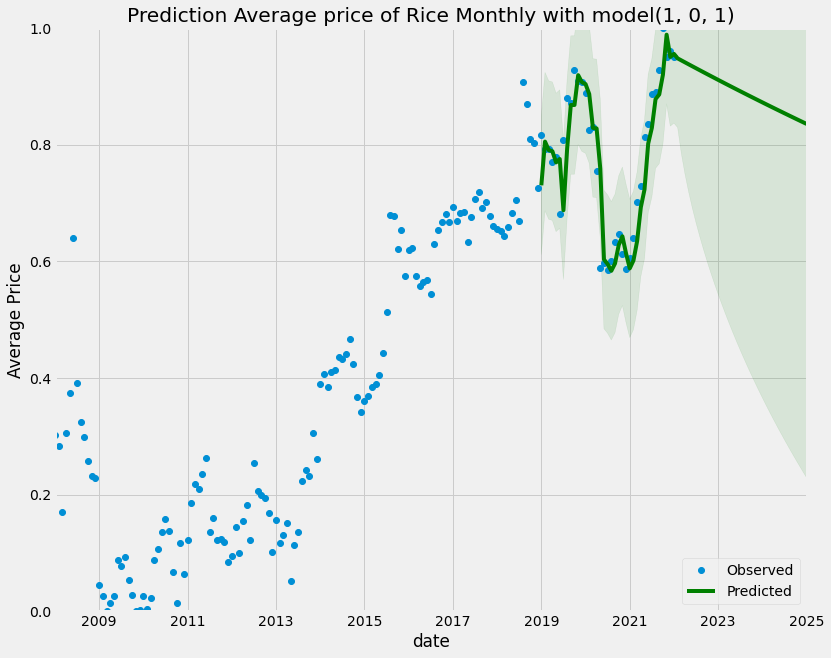

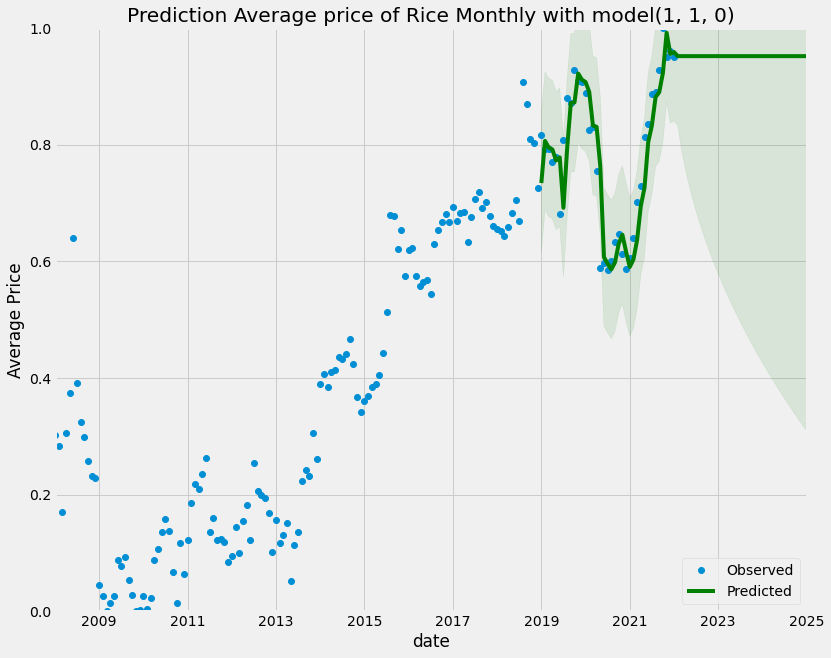

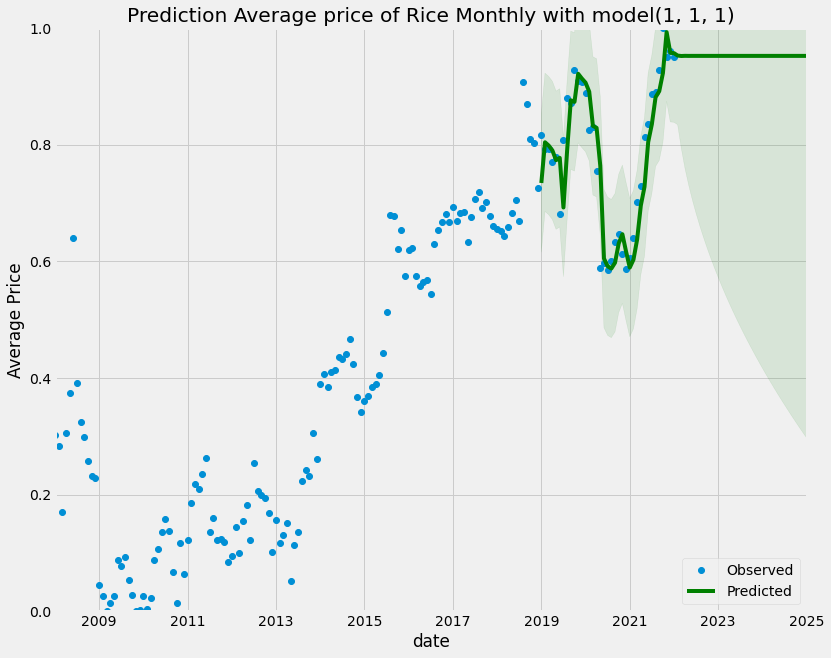

In [26]:
DRM_SARIMAX_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DRM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Rice Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DRM_SARIMAX_models.append(model)

Now we choose (0,1,0)

In [27]:
DRM_SARIMAX_model = DRM_SARIMAX_models[0]

In [28]:
DRM_pred_normalized_SARIMAX  = DRM_SARIMAX_model.predict(pred_st_date, pred_end_date)
DRM_pred_normalized_SARIMAX

2019-01-01    0.725886
2019-02-01    0.816649
2019-03-01    0.792519
2019-04-01    0.791842
2019-05-01    0.770714
                ...   
2024-09-01    0.951017
2024-10-01    0.951017
2024-11-01    0.951017
2024-12-01    0.951017
2025-01-01    0.951017
Freq: MS, Length: 73, dtype: float64

We need to un-normalized the predicted value to get actual price

In [29]:
pred_date = DRM_pred_normalized_SARIMAX.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2019-01-01', '2019-02-01', '2019-03-01', '2019-04-01',
               '2019-05-01', '2019-06-01', '2019-07-01', '2019-08-01',
               '2019-09-01', '2019-10-01', '2019-11-01', '2019-12-01',
               '2020-01-01', '2020-02-01', '2020-03-01', '2020-04-01',
               '2020-05-01', '2020-06-01', '2020-07-01', '2020-08-01',
               '2020-09-01', '2020-10-01', '2020-11-01', '2020-12-01',
               '2021-01-01', '2021-02-01', '2021-03-01', '2021-04-01',
               '2021-05-01', '2021-06-01', '2021-07-01', '2021-08-01',
               '2021-09-01', '2021-10-01', '2021-11-01', '2021-12-01',
               '2022-01-01', '2022-02-01', '2022-03-01', '2022-04-01',
               '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01',
               '2022-09-01', '2022-10-01', '2022-11-01', '2022-12-01',
               '2023-01-01', '2023-02-01', '2023-03-01', '2023-04-01',
               '2023-05-01', '2023-06-01', '2023-07-01', '2023-08-01',
      

In [30]:
DRM_pred_normalized_SARIMAX_df = pd.DataFrame(DRM_pred_normalized_SARIMAX)
DRM_pred_normalized_SARIMAX_df = DRM_pred_normalized_SARIMAX_df[:-1] # the last index doesn't need
DRM_pred_normalized_SARIMAX_df

,0
2019-01-01,0.725886
2019-02-01,0.816649
2019-03-01,0.792519
2019-04-01,0.791842
2019-05-01,0.770714
...,...
2024-08-01,0.951017
2024-09-01,0.951017
2024-10-01,0.951017
2024-11-01,0.951017


#### The Prediction Average Price of Rice Per KG using SARIMAX 

In [31]:
DRM_pred_act_SARIMAX = scaler.inverse_transform(DRM_pred_normalized_SARIMAX_df)
DRM_pred_act_KG_SARIMAX_df = pd.DataFrame(DRM_pred_act_SARIMAX)
DRM_pred_act_KG_SARIMAX_df['date'] = pred_date
DRM_pred_act_KG_SARIMAX_df.columns = ['Predicted Price (KG)', 'date']
DRM_pred_act_KG_SARIMAX_df.set_index('date', inplace=True)
DRM_pred_act_KG_SARIMAX_df

,Predicted Price (KG)
date,
2019-01-01,695.036000
2019-02-01,739.852500
2019-03-01,727.937500
2019-04-01,727.603333
2019-05-01,717.170769
...,...
2024-08-01,806.200000
2024-09-01,806.200000
2024-10-01,806.200000


#### The Prediction Average Price of Rice Per Pyi using SARIMAX 

၁ပြည် = 2.24 KG

In [32]:
DRM_pred_act_Pyi_SARIMAX_df = DRM_pred_act_KG_SARIMAX_df.copy()
DRM_pred_act_Pyi_SARIMAX_df.columns = ['Predicted Price (Pyi)']
DRM_pred_act_Pyi_SARIMAX_df['Predicted Price (Pyi)'] = DRM_pred_act_Pyi_SARIMAX_df['Predicted Price (Pyi)'] * 2.24
DRM_pred_act_Pyi_SARIMAX_df

,Predicted Price (Pyi)
date,
2019-01-01,1556.880640
2019-02-01,1657.269600
2019-03-01,1630.580000
2019-04-01,1629.831467
2019-05-01,1606.462523
...,...
2024-08-01,1805.888000
2024-09-01,1805.888000
2024-10-01,1805.888000


### Linear Regression

In [33]:
temp_df = DRM.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2008-01-01,0.302965
1,2008-02-01,0.282652
2,2008-03-01,0.169602
3,2008-04-01,0.305544
4,2008-05-01,0.373781
...,...,...
164,2021-09-01,0.927413
165,2021-10-01,1.000000
166,2021-11-01,0.950272
167,2021-12-01,0.960145


In [34]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 0   2008-01-01  0.302965  1199145600000000000
 1   2008-02-01  0.282652  1201824000000000000
 2   2008-03-01  0.169602  1204329600000000000
 3   2008-04-01  0.305544  1207008000000000000
 4   2008-05-01  0.373781  1209600000000000000
 ..         ...       ...                  ...
 162 2021-07-01  0.887155  1625097600000000000
 164 2021-09-01  0.927413  1630454400000000000
 166 2021-11-01  0.950272  1635724800000000000
 167 2021-12-01  0.960145  1638316800000000000
 168 2022-01-01  0.951017  1640995200000000000
 
 [140 rows x 3 columns],
           date     price                 time
 9   2008-10-01  0.258102  1222819200000000000
 10  2008-11-01  0.231716  1225497600000000000
 24  2010-01-01  0.026393  1262304000000000000
 26  2010-03-01  0.023110  1267401600000000000
 30  2010-07-01  0.158815  1277942400000000000
 36  2011-01-01  0.121557  1293840000000000000
 38  2011-03-01  0.218260  1298937600000000000
 42  2011-07-01  0.136279  130947

In [35]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1199145600000000000],
        [1201824000000000000],
        [1204329600000000000],
        [1207008000000000000],
        [1209600000000000000],
        [1212278400000000000],
        [1214870400000000000],
        [1217548800000000000],
        [1220227200000000000],
        [1228089600000000000]], dtype=int64),
 array([0.30296519, 0.28265214, 0.16960223, 0.3055438 , 0.37378123,
        0.64075389, 0.391373  , 0.32537114, 0.29922182, 0.22927753]))

In [36]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1222819200000000000],
        [1225497600000000000],
        [1262304000000000000],
        [1267401600000000000],
        [1277942400000000000],
        [1293840000000000000],
        [1298937600000000000],
        [1309478400000000000],
        [1320105600000000000],
        [1356998400000000000]], dtype=int64),
 array([0.25810239, 0.23171604, 0.02639266, 0.02311045, 0.15881536,
        0.1215571 , 0.21825995, 0.13627853, 0.11939518, 0.15612904]))

In [37]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [38]:
DRM_linreg = LinearRegression().fit(X_train, y_train)

In [39]:
print('linear model coeff or slope (w): {}'.format(DRM_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DRM_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DRM_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DRM_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [1.97983728e-18]
linear model intercept (b): -2.365
R-squared score (training): 0.768
R-squared score (test): 0.828


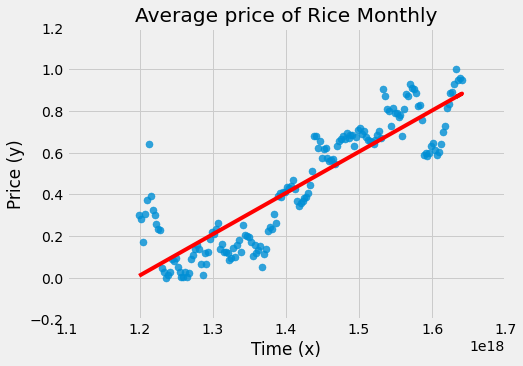

In [40]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DRM_linreg.coef_ * X + DRM_linreg.intercept_, 'r-')
plt.title('Average price of Rice Monthly')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [41]:
DRM_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DRM_linear_predict['time'] = DRM_linear_predict['date'].apply(lambda x: x.value)
DRM_linear_predict

,date,time
0,2019-01-01,1546300800000000000
1,2019-02-01,1548979200000000000
2,2019-03-01,1551398400000000000
3,2019-04-01,1554076800000000000
4,2019-05-01,1556668800000000000
...,...,...
68,2024-09-01,1725148800000000000
69,2024-10-01,1727740800000000000
70,2024-11-01,1730419200000000000
71,2024-12-01,1733011200000000000


In [42]:
time_predict = np.array(DRM_linear_predict['time']).reshape((-1, 1))
DRM_linear_predict['price'] = DRM_linreg.predict(time_predict)
DRM_linear_predict

,date,time,price
0,2019-01-01,1546300800000000000,0.696238
1,2019-02-01,1548979200000000000,0.701541
2,2019-03-01,1551398400000000000,0.706331
3,2019-04-01,1554076800000000000,0.711633
4,2019-05-01,1556668800000000000,0.716765
...,...,...,...
68,2024-09-01,1725148800000000000,1.050328
69,2024-10-01,1727740800000000000,1.055460
70,2024-11-01,1730419200000000000,1.060763
71,2024-12-01,1733011200000000000,1.065894


In [43]:
DRM_linear_normalized_predict = DRM_linear_predict.copy()
DRM_linear_normalized_predict = DRM_linear_normalized_predict[['date', 'price']]
DRM_linear_normalized_predict.set_index('date', inplace=True)
DRM_linear_normalized_predict

,price
date,
2019-01-01,0.696238
2019-02-01,0.701541
2019-03-01,0.706331
2019-04-01,0.711633
2019-05-01,0.716765
...,...
2024-09-01,1.050328
2024-10-01,1.055460
2024-11-01,1.060763


#### The Prediction Average Price of Rice Per KG using Linear Regression

In [44]:
DRM_pred_act_linear = scaler.inverse_transform(DRM_linear_normalized_predict)
DRM_pred_act_KG_linear_df = pd.DataFrame(DRM_pred_act_linear)
DRM_pred_act_KG_linear_df['date'] = DRM_linear_predict['date']
DRM_pred_act_KG_linear_df.columns = ['Predicted Price (KG)', 'date']
DRM_pred_act_KG_linear_df.set_index('date', inplace=True)
DRM_pred_act_KG_linear_df

,Predicted Price (KG)
date,
2019-01-01,680.396698
2019-02-01,683.015080
2019-03-01,685.380071
2019-04-01,687.998454
2019-05-01,690.532372
...,...
2024-09-01,855.237076
2024-10-01,857.770995
2024-11-01,860.389377


#### The Prediction Average Price of Rice Per Pyi using Linear Regression

၁ပြည် = 2.24 KG

In [45]:
DRM_pred_act_Pyi_linear_df = DRM_pred_act_KG_linear_df.copy()
DRM_pred_act_Pyi_linear_df.columns = ['Predicted Price (Pyi)']
DRM_pred_act_Pyi_linear_df['Predicted Price (Pyi)'] = DRM_pred_act_Pyi_linear_df['Predicted Price (Pyi)'] * 2.24
DRM_pred_act_Pyi_linear_df

,Predicted Price (Pyi)
date,
2019-01-01,1524.088603
2019-02-01,1529.953780
2019-03-01,1535.251359
2019-04-01,1541.116536
2019-05-01,1546.792513
...,...
2024-09-01,1915.731050
2024-10-01,1921.407028
2024-11-01,1927.272205
